This notebook trains the 5 gene-specific RNA-Protein linear models, estimates the protein count in the expression dataset and creates all plots regarding the linear models for protein expression estimation.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import TheilSenRegressor
from sklearn.datasets import make_regression
from sklearn.metrics import r2_score
import pickle
import matplotlib.pyplot as plt
from scipy.stats import spearmanr,pearsonr
import warnings
warnings.filterwarnings('ignore')
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
import scipy.stats as stats

In [2]:
df_data = pd.read_csv('data/expression/whole_dataset.csv').dropna()
df_data = df_data.loc[df_data["Gene"].isin(["IL2RA_HUMAN","IL2RB_HUMAN","IL2RG_HUMAN","STA5A_HUMAN","STA5B_HUMAN"])]
df_tissues = pd.read_csv("data/expression/tissues_dataset.csv").dropna()
df_tissues = df_tissues.loc[df_tissues["Gene"].isin(["IL2RA_HUMAN","IL2RB_HUMAN","IL2RG_HUMAN","STA5A_HUMAN","STA5B_HUMAN"])]

### Training of linear models for IL-2RA, IL-2RB, IL-2RG, STAT5A and STAT5B

Training is done with the PBMCs data of all genes except IL-2RG, which is trained with the tissues data due to its higher variability.

In [3]:
# IL2RA and IL2RB -> IL2 receptor quantification dataset
MAE_dict = {}
gene_list = ["IL2RA_HUMAN","IL2RB_HUMAN"]
df_lin = pd.DataFrame(columns=["Gene","Intercept","Slope","r2"])
cells = []
for gene in gene_list:
    df_gene = df_data.loc[df_data["Gene"]==gene]
    cells += df_gene["Cell"].to_list()
    TPM = df_gene.loc[df_gene["Prot. count dataset num."]==6]["Log2 TPM"]
    Prot = df_gene.loc[df_gene["Prot. count dataset num."]==6]["Log10 Prot. count"]
    model = TheilSenRegressor(random_state=0).fit(np.array(TPM).reshape(-1, 1), np.array(Prot).reshape(-1, 1))
    df_lin.loc[len(df_lin.index)] = [gene, model.intercept_, model.coef_[0], r2_score(Prot, model.predict(np.array(TPM).reshape(-1, 1)))]
    MAE_dict[gene] = np.mean(abs(model.intercept_+TPM.values*model.coef_[0]-Prot.values))
    print(gene + ": r_p= "+str(pearsonr(TPM, Prot).statistic))
# IL2RG is constitutively expressed in immune cells so we take the tissues dataset as training (more variability)
gene = "IL2RG_HUMAN"
df_gene = df_tissues.loc[df_tissues["Gene"]==gene]
TPM = df_gene["Log2 TPM"]
Prot = df_gene["Log10 Prot. count"]
model = TheilSenRegressor(random_state=0).fit(np.array(TPM).reshape(-1, 1), np.array(Prot).reshape(-1, 1))
df_lin.loc[len(df_lin.index)] = [gene, model.intercept_, model.coef_[0], r2_score(Prot, model.predict(np.array(TPM).reshape(-1, 1)))]
MAE_dict[gene] = np.mean(abs(model.intercept_+TPM.values*model.coef_[0]-Prot.values))
print(gene + ": r_p= "+str(pearsonr(TPM, Prot).statistic))
# STAT data from PBMCs dataset
gene_list = ["STA5A_HUMAN","STA5B_HUMAN"]
for gene in gene_list:
    df_gene = df_data.loc[(df_data["Gene"]==gene)]
    cells += df_gene["Cell"].to_list()
    TPM = df_gene["Log2 TPM"]
    Prot = df_gene["Log10 Prot. count"]
    model = TheilSenRegressor(random_state=0).fit(np.array(TPM).reshape(-1, 1), np.array(Prot).reshape(-1, 1))
    df_lin.loc[len(df_lin.index)] = [gene, model.intercept_, model.coef_[0], r2_score(Prot, model.predict(np.array(TPM).reshape(-1, 1)))]
    MAE_dict[gene] = np.mean(abs(model.intercept_+TPM.values*model.coef_[0]-Prot.values))
    print(gene + ": r_p= "+str(pearsonr(TPM, Prot).statistic))
df_lin_og = df_lin.copy()

IL2RA_HUMAN: r_p= 0.9650993007564517
IL2RB_HUMAN: r_p= 0.9834338006642452
IL2RG_HUMAN: r_p= 0.7017565680653126
STA5A_HUMAN: r_p= 0.7978107064376164
STA5B_HUMAN: r_p= 0.7113106904663902


In [4]:
# Save results
df_lin.to_csv('data/lin_models/linear_models.csv')

In [5]:
color_sim = [(68/255, 138/255, 255/255),(0, 150/255, 136/255),(139/255, 195/255, 74/255),(255/255, 193/255, 7/255),(255/255, 152/255, 0),(244/255, 67/255, 54/255),(173/255, 20/255, 87/255)]
fig, ax = plt.subplots(1,1,figsize=(9, 8), dpi=600)
i = 0
for gene in df_lin["Gene"]:
    df_gene = df_data.loc[df_data["Gene"] == gene]
    if gene == "IL2RA_HUMAN":
        df_gene = df_gene.loc[df_gene["Prot. count dataset num."]==6]
    elif gene == "IL2RB_HUMAN":
        df_gene = df_gene.loc[df_gene["Prot. count dataset num."]==6]
    elif gene == "IL2RG_HUMAN":
        df_gene = df_tissues.loc[df_tissues["Gene"] == gene]
    TPM = np.linspace(0, 12, 40)
    Prot = df_lin.loc[df_lin["Gene"]==gene]["Intercept"].values[0] + TPM * df_lin.loc[df_lin["Gene"]==gene]["Slope"].values[0]
    plt.plot(TPM, Prot, color=color_sim[i], linewidth=4, label = gene.split("_HUMAN")[0] + " $(MAE="+str(round(MAE_dict[gene],2))+")$")
    plt.scatter(df_gene["Log2 TPM"].values, df_gene["Log10 Prot. count"].values, s=60, color=color_sim[i], alpha = 1)
    i += 1
#ax.set_ylim([0, 4.5])
ax.spines["bottom"].set_linewidth(4)
ax.spines["left"].set_linewidth(4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.tick_params(axis='x', labelsize=22)
ax.tick_params(axis='y', labelsize=22)
plt.xticks([0, 2, 4, 6, 8, 10, 12])
plt.legend(loc="best", fontsize=18)
plt.ylabel('log10(Protein count)', fontsize=25)
plt.xlabel('log2(TPM)', fontsize=25)
plt.savefig('figures/lin_models/corr_IL2.pdf', bbox_inches='tight', transparent=True)
plt.close()

### Linear RNA-Protein model validation

To validate the linear models, we split the training data into train and test multiple times and evalute them in these datasets + test dataset of unrelated data.

In [6]:
from multiprocessing import Pool
from collections import Counter

def parallel_gen_lin_model(df_data, gene_list, num_samples, num_cores):
    param_parallel = []
    for i in range(0,num_samples):
        param_parallel.append([df_data.loc[df_data["Sample"]==i],gene_list])
    with Pool(processes=num_cores) as pool:
        out_vec = pool.map(gen_lin_model, param_parallel)
    return pd.concat(out_vec, axis=0)

def gen_lin_model(list_df):
    df_sample = list_df[0]
    gene_list = list_df[1]
    df_lin_sample = pd.DataFrame(columns=["Sample","Gene","Intercept","Slope","r2_train","MAE_train"])
    for gene in gene_list:
        TPM = df_sample.loc[df_sample["Gene"]==gene,"Log2 TPM"].values
        Prot = df_sample.loc[df_sample["Gene"]==gene,"Log10 Prot. count"].values
        model = TheilSenRegressor(random_state=0).fit(TPM.reshape(-1, 1), Prot)
        df_lin_sample.loc[len(df_lin_sample.index)] = [df_sample["Sample"].values[0], gene, model.intercept_, model.coef_[0], r2_score(Prot, model.predict(TPM.reshape(-1, 1))),np.mean(abs(model.predict(TPM.reshape(-1, 1))-Prot))]
    return df_lin_sample

def lin_model_sample(list_df):
    df_sample_data = list_df[0]
    df_sample_lin = list_df[1]
    gene_list = list_df[2]
    for gene in gene_list:
        df_sample_data.loc[df_sample_data["Gene"]==gene,"Prot. count predict"] = df_sample_lin.loc[df_sample_lin["Gene"]==gene,"Intercept"].values[0]+df_sample_lin.loc[df_sample_lin["Gene"]==gene,"Slope"].values[0]*df_sample_data.loc[df_sample_data["Gene"]==gene,"Log2 TPM"]
    return df_sample_data

def parallel_sim(df_data, df_lin, gene_list, num_samples, num_cores):
    param_parallel = []
    for i in range(0,num_samples):
        param_parallel.append([df_data.loc[df_data["Sample"]==i],df_lin.loc[df_lin["Sample"]==i],gene_list])
    with Pool(processes=num_cores) as pool:
        out_vec = pool.map(lin_model_sample, param_parallel)
    return pd.concat(out_vec, axis=0)

In [31]:
# Get datasets
df_train_val = pd.concat([df_data.loc[(df_data["Gene"].isin(["IL2RA_HUMAN","IL2RB_HUMAN"]))&(df_data["Prot. count dataset num."]==6)],df_data.loc[(df_data["Gene"].isin(["STA5A_HUMAN","STA5B_HUMAN"]))],df_tissues.loc[df_tissues["Gene"].isin(["IL2RG_HUMAN"])]])
df_train_val.reset_index(drop=True,inplace=True)
df_test_slice = pd.concat([df_tissues.loc[df_tissues["Gene"].isin(["IL2RA_HUMAN","IL2RB_HUMAN","STA5A_HUMAN","STA5B_HUMAN"])],df_data.loc[(df_data["Gene"].isin(["IL2RG_HUMAN"]))&(df_data["Prot. count dataset num."]==6)],df_data.loc[(df_data["Gene"].isin(["IL2RB_HUMAN"]))&(df_data["Prot. count dataset num."]==1)&(~df_data["Cell"].isin(["MO.nonclassical","B.naive"]))]])
df_test_slice.loc[df_test_slice["Gene"]=="IL2RB_HUMAN","Log10 Prot. count"] = np.log10(10**df_test_slice.loc[df_test_slice["Gene"]=="IL2RB_HUMAN","Log10 Prot. count"]*0.5)
df_test_slice.reset_index(drop=True,inplace=True)

In [32]:
num_samples = 100
genes_shared = ["STA5A_HUMAN", "STA5B_HUMAN"]
# Cell types shared between STA5A and STA5B
common_cells = sorted(
    set(df_train_val.loc[df_train_val["Gene"] == genes_shared[0], "Cell"])
    &
    set(df_train_val.loc[df_train_val["Gene"] == genes_shared[1], "Cell"])
)

df_train_list = []
df_val_list = []
df_test_list = []
for i in range(num_samples):
    # Select the same 3 cell types for STA5A and STA5B
    selected_cells = np.random.default_rng(i).choice(
        common_cells, size=3, replace=False
    )
    # Validation rows for STA5A and STA5B
    df_val_shared = df_train_val[
        df_train_val["Gene"].isin(genes_shared) &
        df_train_val["Cell"].isin(selected_cells)
    ]
    # Random validation rows for other genes
    df_val_other = (
        df_train_val[~df_train_val["Gene"].isin(genes_shared)]
        .groupby("Gene")
        .sample(n=3, random_state=i)
    )
    
    df_val_slice = pd.concat([df_val_shared, df_val_other])
    df_train_slice = df_train_val.drop(df_val_slice.index)
    df_train_slice["Sample"] = i
    df_val_slice["Sample"] = i
    df_test_slice["Sample"] = i
    df_train_list.append(df_train_slice)
    df_val_list.append(df_val_slice)
    df_test_list.append(df_test_slice.copy())
    
df_train = pd.concat(df_train_list, ignore_index=True)
df_val = pd.concat(df_val_list, ignore_index=True)
df_test = pd.concat(df_test_list, ignore_index=True)

In [33]:
# Train models
gene_list = ["IL2RA_HUMAN","IL2RB_HUMAN","IL2RG_HUMAN","STA5A_HUMAN","STA5B_HUMAN"]
num_cores = 12
df_lin = parallel_gen_lin_model(df_train, gene_list, num_samples, num_cores)

In [34]:
# Simulate for the training set of each sample
df_train["Prot. count predict"] = np.nan
df_train = parallel_sim(df_train, df_lin, gene_list, num_samples, num_cores)

# Simulate for the validation set of each sample
df_val["Prot. count predict"] = np.nan
df_val = parallel_sim(df_val, df_lin, gene_list, num_samples, num_cores)

# Simulate for the test set of each sample
df_test["Prot. count predict"] = np.nan
df_test = parallel_sim(df_test, df_lin, gene_list, num_samples, num_cores)

In [35]:
# Since STAT5A and STAT5B are paralogs that are counted as the same protein (STAT5) in the model, we sum their inputs and outputs
df_STAT5 = df_train.loc[(df_train["Gene"]=="STA5A_HUMAN")]
df_STAT5B = df_train.loc[(df_train["Gene"]=="STA5B_HUMAN")]
df_STAT5 = df_STAT5.loc[df_STAT5["Cell"].isin(list(set(df_STAT5["Cell"].to_list())&set(df_STAT5B["Cell"].to_list())))]
df_STAT5B = df_STAT5B.loc[df_STAT5B["Cell"].isin(list(set(df_STAT5["Cell"].to_list())&set(df_STAT5B["Cell"].to_list())))]
df_STAT5["Log2 TPM"] = np.log2(2**df_STAT5["Log2 TPM"].values+2**df_STAT5B["Log2 TPM"].values)
df_STAT5["Log10 Prot. count"] = np.log10(10**df_STAT5["Log10 Prot. count"].values+10**df_STAT5B["Log10 Prot. count"].values)
df_STAT5["Prot. count predict"] = np.log10(10**df_STAT5["Prot. count predict"].values+10**df_STAT5B["Prot. count predict"].values)
df_train = df_train.loc[df_train["Gene"].isin(["IL2RA_HUMAN","IL2RB_HUMAN","IL2RG_HUMAN"])]
df_train = pd.concat([df_train, df_STAT5], ignore_index=True)
df_train.loc[(df_train["Gene"]=="STA5A_HUMAN"),"Gene"] = "STAT5_HUMAN"

In [36]:
# Since STAT5A and STAT5B are paralogs that are counted as the same protein (STAT5) in the model, we sum their inputs and outputs
df_STAT5 = df_val.loc[(df_val["Gene"]=="STA5A_HUMAN")]
df_STAT5B = df_val.loc[(df_val["Gene"]=="STA5B_HUMAN")]
df_STAT5 = df_STAT5.loc[df_STAT5["Cell"].isin(list(set(df_STAT5["Cell"].to_list())&set(df_STAT5B["Cell"].to_list())))]
df_STAT5B = df_STAT5B.loc[df_STAT5B["Cell"].isin(list(set(df_STAT5["Cell"].to_list())&set(df_STAT5B["Cell"].to_list())))]
df_STAT5["Log2 TPM"] = np.log2(2**df_STAT5["Log2 TPM"].values+2**df_STAT5B["Log2 TPM"].values)
df_STAT5["Log10 Prot. count"] = np.log10(10**df_STAT5["Log10 Prot. count"].values+10**df_STAT5B["Log10 Prot. count"].values)
df_STAT5["Prot. count predict"] = np.log10(10**df_STAT5["Prot. count predict"].values+10**df_STAT5B["Prot. count predict"].values)
df_val = df_val.loc[df_val["Gene"].isin(["IL2RA_HUMAN","IL2RB_HUMAN","IL2RG_HUMAN"])]
df_val = pd.concat([df_val, df_STAT5], ignore_index=True)
df_val.loc[(df_val["Gene"]=="STA5A_HUMAN"),"Gene"] = "STAT5_HUMAN"

In [37]:
# Since STAT5A and STAT5B are paralogs that are counted as the same protein (STAT5) in the model, we sum their inputs and outputs
df_STAT5 = df_test.loc[(df_test["Gene"]=="STA5A_HUMAN")]
df_STAT5B = df_test.loc[(df_test["Gene"]=="STA5B_HUMAN")]
df_STAT5 = df_STAT5.loc[df_STAT5["Cell"].isin(list(set(df_STAT5["Cell"].to_list())&set(df_STAT5B["Cell"].to_list())))]
df_STAT5B = df_STAT5B.loc[df_STAT5B["Cell"].isin(list(set(df_STAT5["Cell"].to_list())&set(df_STAT5B["Cell"].to_list())))]
df_STAT5["Log2 TPM"] = np.log2(2**df_STAT5["Log2 TPM"].values+2**df_STAT5B["Log2 TPM"].values)
df_STAT5["Log10 Prot. count"] = np.log10(10**df_STAT5["Log10 Prot. count"].values+10**df_STAT5B["Log10 Prot. count"].values)
df_STAT5["Prot. count predict"] = np.log10(10**df_STAT5["Prot. count predict"].values+10**df_STAT5B["Prot. count predict"].values)
df_test = df_test.loc[df_test["Gene"].isin(["IL2RB_HUMAN","IL2RG_HUMAN"])]
df_test = pd.concat([df_test, df_STAT5], ignore_index=True)
df_test.loc[(df_test["Gene"]=="STA5A_HUMAN"),"Gene"] = "STAT5_HUMAN"

In [38]:
# Get error x point
df_train["Error"] = (df_train["Log10 Prot. count"]-df_train["Prot. count predict"]).abs()
df_val["Error"] = (df_val["Log10 Prot. count"]-df_val["Prot. count predict"]).abs()
df_test["Error"] = (df_test["Log10 Prot. count"]-df_test["Prot. count predict"]).abs()

In [39]:
df_train["Gene_Sample"] = df_train["Gene"]+"__"+df_train["Sample"].astype("str")
df_train_MAE = pd.DataFrame(df_train[["Gene_Sample","Error"]].groupby("Gene_Sample")["Error"].mean())
df_train_MAE["Gene"] = [index.split("__")[0] for index in df_train_MAE.index]

df_val["Gene_Sample"] = df_val["Gene"]+"__"+df_val["Sample"].astype("str")
df_val_MAE = pd.DataFrame(df_val[["Gene_Sample","Error"]].groupby("Gene_Sample")["Error"].mean())
df_val_MAE["Gene"] = [index.split("__")[0] for index in df_val_MAE.index]

df_test["Gene_Sample"] = df_test["Gene"]+"__"+df_test["Sample"].astype("str")
df_test_MAE = pd.DataFrame(df_test[["Gene_Sample","Error"]].groupby("Gene_Sample")["Error"].mean())
df_test_MAE["Gene"] = [index.split("__")[0] for index in df_test_MAE.index]

In [40]:
df_val_MAE["Error"].mean()/df_train_MAE["Error"].mean()

1.3153887695546336

In [41]:
df_test_MAE["Error"].mean()/df_train_MAE["Error"].mean()

2.3907102875293327

,Dataset type,RNA dataset num.,Prot. count dataset num.,Cell,Gene,Log2 TPM,Log10 Prot. count,Sample,Prot. count predict,Error,Gene_Sample
0,Immune,1.0,6.0,T4.naive,IL2RA_HUMAN,4.709007,2.371376,0,2.021433,0.349943,IL2RA_HUMAN__0
1,Immune,1.0,6.0,T4.naive,IL2RB_HUMAN,4.947811,1.400714,0,1.457084,0.056370,IL2RB_HUMAN__0
2,Immune,1.0,6.0,T8.naive,IL2RA_HUMAN,2.286676,1.163511,0,1.232720,0.069209,IL2RA_HUMAN__0
3,Immune,3.0,6.0,mTregs,IL2RB_HUMAN,9.173927,2.861586,0,3.095332,0.233746,IL2RB_HUMAN__0
4,Immune,3.0,6.0,nTregs,IL2RA_HUMAN,9.160376,3.471043,0,3.470802,0.000242,IL2RA_HUMAN__0
...,...,...,...,...,...,...,...,...,...,...,...
5095,Immune,1.0,6.0,T8.M,STAT5_HUMAN,7.187087,5.467213,99,5.425316,0.041897,STAT5_HUMAN__99
5096,Immune,1.0,6.0,T4_IL2RAlow,STAT5_HUMAN,7.456091,5.478671,99,5.492801,0.014129,STAT5_HUMAN__99
5097,Immune,1.0,1.0,T4.CM_IL2RAlow,STAT5_HUMAN,7.654365,5.564064,99,5.525053,0.039012,STAT5_HUMAN__99
5098,Immune,1.0,1.0,T4.EM_IL2RAlow,STAT5_HUMAN,7.490437,5.474687,99,5.509497,0.034809,STAT5_HUMAN__99


In [50]:
df_train.groupby("Sample").apply(lambda g: pearsonr(g["Log10 Prot. count"], g["Prot. count predict"])[0]).mean()

0.9797429970325156

In [51]:
df_val.groupby("Sample").apply(lambda g: pearsonr(g["Log10 Prot. count"], g["Prot. count predict"])[0]).mean()

0.9773198343920291

In [52]:
df_test.groupby("Sample").apply(lambda g: pearsonr(g["Log10 Prot. count"], g["Prot. count predict"])[0]).mean()

0.958734646128229

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

color_sim = [(68/255, 138/255, 255/255),(0, 150/255, 136/255),(139/255, 195/255, 74/255),(255/255, 193/255, 7/255)]
genes = ["IL2RA_HUMAN", "IL2RB_HUMAN", "IL2RG_HUMAN", "STAT5_HUMAN"]
labels = [g.split("_HUMAN")[0] for g in genes]
datasets = [("Training set", df_train_MAE), ("Validation set", df_val_MAE), ("Test set", df_test_MAE)]

fig, ax = plt.subplots(1, 1, figsize=(10, 7), dpi=400)

n_genes = len(genes)
box_w = 0.6
group_gap = 0.1                         # extra space between datasets
group_width = n_genes * box_w
group_step = group_width + group_gap

xticks = []
for d, (name, df_d) in enumerate(datasets):
    start = d * group_step
    for g, gene in enumerate(genes):
        pos = start + g * box_w
        data = df_d.loc[df_d["Gene"] == gene, "Error"].dropna().values
        ax.boxplot(
            [data],
            positions=[pos],
            widths=box_w * 0.85,
            patch_artist=True,
            boxprops=dict(facecolor=color_sim[g], edgecolor="black", linewidth=1.5),
            medianprops=dict(color="black", linewidth=1.5),
            whiskerprops=dict(color="black", linewidth=1.5),
            capprops=dict(color="black", linewidth=1.5),
            flierprops=dict(marker="o", markersize=3, markerfacecolor="black", markeredgecolor="black", alpha=0.5),
        )
    xticks.append(start + (group_width - box_w) / 2)

# Spine formatting
ax.spines["bottom"].set_linewidth(4)
ax.spines["left"].set_linewidth(4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Tick formatting
ax.xaxis.set_tick_params(width=4, length=8)
ax.yaxis.set_tick_params(width=4, length=8)
ax.tick_params(axis="x", labelsize=17)
ax.tick_params(axis="y", labelsize=17)

# Labels
ax.set_xticks(xticks)
ax.set_xticklabels([name for name, _ in datasets], fontsize=17)
ax.set_ylabel("MAE (log10 Prot. count)", fontsize=20)

# Legend with one entry per gene
handles = [Patch(facecolor=color_sim[i], edgecolor="black", linewidth=1.5, label=labels[i]) for i in range(n_genes)]
ax.legend(handles=handles, loc="best", fontsize=15)

plt.tight_layout()
plt.savefig(
    "figures/lin_models/Plot_box_train_val_test_genes.pdf",
    transparent=True,
    bbox_inches="tight"
)
plt.close()

In [35]:
from sklearn.linear_model import LinearRegression

In [78]:
# Train LR model with the test data
TPM = df_test.loc[df_test["Gene_Sample"]=="IL2RB_HUMAN__0","Log2 TPM"]
Prot = df_test.loc[df_test["Gene_Sample"]=="IL2RB_HUMAN__0","Log10 Prot. count"]
model = LinearRegression().fit(np.array(TPM).reshape(-1, 1), np.array(Prot).reshape(-1, 1)
                               
# Train LR model with the train data
df_gene = df_data.loc[df_data["Gene"]=="IL2RB_HUMAN"]
TPM2 = df_gene.loc[df_gene["Prot. count dataset num."]==6]["Log2 TPM"]
Prot2 = df_gene.loc[df_gene["Prot. count dataset num."]==6]["Log10 Prot. count"]
model2 = LinearRegression().fit(np.array(TPM2).reshape(-1, 1), np.array(Prot2).reshape(-1, 1))  
                               

SyntaxError: '(' was never closed (3730606192.py, line 4)

In [82]:
print("Diference in slope: "+str(model.coef_[0][0]-model2.coef_[0][0]))

Diference in slope: 0.01339263741736485


In [83]:
print("Diference in intercept: "+str(model.intercept_[0]-model2.intercept_[0]))

Diference in intercept: 0.7237629540650201


In [85]:
df_test.loc[df_test["Gene_Sample"]=="IL2RB_HUMAN__0","Log2 TPM"].mean()

7.893735206269301

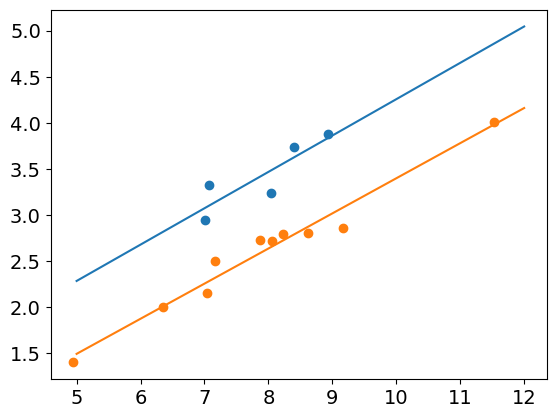

In [49]:
plt.scatter(TPM,Prot)
plt.plot(np.linspace(5,12,10),model.intercept_+np.linspace(5,12,10)*model.coef_[0])
plt.scatter(TPM2,Prot2)
plt.plot(np.linspace(5,12,10),model2.intercept_+np.linspace(5,12,10)*model2.coef_[0])

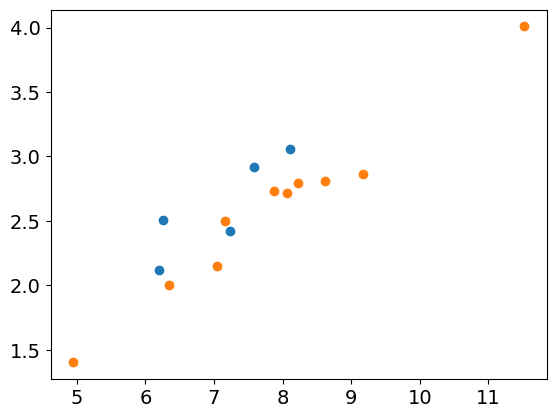

In [66]:
plt.scatter(TPM-0.82,Prot-0.82)
plt.scatter(TPM2,Prot2)

In [71]:
df_test.loc[df_test["Gene"]=="IL2RB_HUMAN","Log10 Prot. count"] = df_test.loc[df_test["Gene"]=="IL2RB_HUMAN","Log10 Prot. count"]-0.8
df_test["Error"] = (df_test["Log10 Prot. count"]-df_test["Prot. count predict"]).abs()
df_test["Gene_Sample"] = df_test["Gene"]+"__"+df_test["Sample"].astype("str")
df_test_MAE = pd.DataFrame(df_test[["Gene_Sample","Error"]].groupby("Gene_Sample")["Error"].mean())
df_test_MAE["Gene"] = [index.split("__")[0] for index in df_test_MAE.index]

In [77]:
df_train_MAE.loc[df_train_MAE["Gene"]=="IL2RB_HUMAN","Error"].median()

0.10698699688792843

In [76]:
df_val_MAE.loc[df_val_MAE["Gene"]=="IL2RB_HUMAN","Error"].median()

0.15712993475213333

In [75]:
df_test_MAE.loc[df_test_MAE["Gene"]=="IL2RB_HUMAN","Error"].median()

0.16904992511094102

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

color_sim = [(68/255, 138/255, 255/255),(0, 150/255, 136/255),(139/255, 195/255, 74/255),(255/255, 193/255, 7/255)]
genes = ["IL2RA_HUMAN", "IL2RB_HUMAN", "IL2RG_HUMAN", "STAT5_HUMAN"]
labels = [g.split("_HUMAN")[0] for g in genes]
datasets = [("Training set", df_train_MAE), ("Validation set", df_val_MAE), ("Test set", df_test_MAE)]

fig, ax = plt.subplots(1, 1, figsize=(10, 7), dpi=400)

n_genes = len(genes)
box_w = 0.6
group_gap = 0.1                         # extra space between datasets
group_width = n_genes * box_w
group_step = group_width + group_gap

xticks = []
for d, (name, df_d) in enumerate(datasets):
    start = d * group_step
    for g, gene in enumerate(genes):
        pos = start + g * box_w
        data = df_d.loc[df_d["Gene"] == gene, "Error"].dropna().values
        ax.boxplot(
            [data],
            positions=[pos],
            widths=box_w * 0.85,
            patch_artist=True,
            boxprops=dict(facecolor=color_sim[g], edgecolor="black", linewidth=1.5),
            medianprops=dict(color="black", linewidth=1.5),
            whiskerprops=dict(color="black", linewidth=1.5),
            capprops=dict(color="black", linewidth=1.5),
            flierprops=dict(marker="o", markersize=3, markerfacecolor="black", markeredgecolor="black", alpha=0.5),
        )
    xticks.append(start + (group_width - box_w) / 2)

# Spine formatting
ax.spines["bottom"].set_linewidth(4)
ax.spines["left"].set_linewidth(4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Tick formatting
ax.xaxis.set_tick_params(width=4, length=8)
ax.yaxis.set_tick_params(width=4, length=8)
ax.tick_params(axis="x", labelsize=17)
ax.tick_params(axis="y", labelsize=17)

# Labels
ax.set_xticks(xticks)
ax.set_xticklabels([name for name, _ in datasets], fontsize=17)
ax.set_ylabel("MAE (log10 Prot. count)", fontsize=20)

# Legend with one entry per gene
handles = [Patch(facecolor=color_sim[i], edgecolor="black", linewidth=1.5, label=labels[i]) for i in range(n_genes)]
ax.legend(handles=handles, loc="best", fontsize=15)

plt.tight_layout()
plt.savefig(
    "figures/lin_models/Plot_box_train_val_test_genes2.pdf",
    transparent=True,
    bbox_inches="tight"
)
plt.close()